In [1]:
import seaborn as sb
import numpy as np
import random
import math
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import functools as ft
import statistics
import scipy as sc

In [2]:
def get_pvalue_info_H1 (pvalue_generator, clr = "#00008B", label = "", level_array = [0.05, 0.01], mode_output = 0):
    table = [0]*len(level_array) # на i-ом месте стоит частота отвержения гипотезы на уровне alpha_i
    pvalue = pvalue_generator()
    N = len(pvalue)
    alpha = level_array

    if(N < 5):
        print("how am i supposed to test your criterion based on < 5 p-value values?", end = "\n")
        print("как я должен тестить ваш критерий, основываясь на < 5 значениях p-value?", end = "\n")
        print("anyway: ", end = "\n")

    for j in range ( len(alpha) ):
        freq = 0
        for p in pvalue:
            if p<alpha[j]:
                freq+=1/N
        table[j] = freq
        # заполнили табличку

    if(mode_output == 0): #на экран ничего, только возвращаем табличку
        return(table)

    if(mode_output == 1): # на экран только график ЭФР пи-вэлью
        l = np.linspace(0,1,100) # пока по умолчанию точность 1/100
        plt.legend()
        plt.title("график ЭФР пи-вэлью при вашей H1")
        plt.plot(l, sc.stats.ecdf(pvalue).cdf.evaluate(l), color = clr, label = label)
        plt.plot(l,l, color =  "#013220")
      
        return(table)

    if(mode_output == 2): #на экран только табличку
        for j in range ( len(level_array) ):
            print("частота отклонений H0 на уровне значимости ", alpha[j], ": ", table[j], end='\n')
        return(table)

    if(mode_output == 3): #на экран табличку и график ЭФР пи-вэлью
        l = np.linspace(0,1,100) # пока по умолчанию точность 1/100
        plt.title("график ЭФР пи-вэлью при вашей H1")
        plt.plot(l, sc.stats.ecdf(pvalue).cdf.evaluate(l), color = "#00008B")
        plt.plot(l,l, color = "#013220")
        plt.show()

        for j in range ( len(level_array) ):
             print("частота отклонений H0 на уровне значимости ", alpha[j], ": ", table[j], end='\n')
        return(table)

In [3]:
сложный cvm для нормального против стьюдент 5

SyntaxError: invalid syntax (1176007858.py, line 1)

student 5


C:\Users\MI\AppData\Local\Temp\ipykernel_13396\634817638.py:25: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


N(8,8)


[0.03, 0]

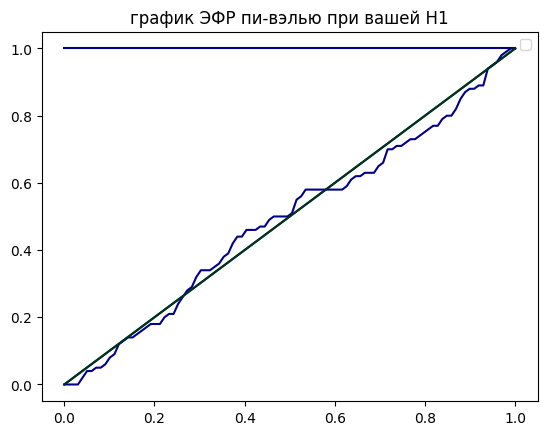

In [3]:
cvm_loaded = np.loadtxt('complex_cvm_values(normal).txt')
def F(x, mu, sigma2):
    return sc.stats.norm.cdf(x, mu, np.sqrt(sigma2))
    
def norm_cvm_stat(n, x):
    y = np.sort(x)
    return(1/(12*n)+np.sum([((2*i-1)/(2*n) - F(y[i-1], np.mean(x), np.var(x)))**2 for i in range(1, n)]))
    
N = 100 #размер выборки пи вэлью
n = 2000 # размер выборки на основе которой считаю статистику
cvm = [0]*N
pval = [0]*N

for k in range(N):
    x = sc.stats.t.rvs(5, size = n)
    pval[k] = 1 - sc.stats.ecdf(cvm_loaded).cdf.evaluate(norm_cvm_stat(n, x))

def a(x):
    return(x)

print("student 5")
b = ft.partial(a,pval)

get_pvalue_info_H1 (b, level_array = [0.05, 0.01], mode_output = 1)



for k in range(N):
    x = np.random.normal(8, 8, size = n)
    pval[k] = 1 - sc.stats.ecdf(cvm_loaded).cdf.evaluate(norm_cvm_stat(n, x))
print("N(8,8)")
b = ft.partial(a,pval)
get_pvalue_info_H1 (b, level_array = [0.05, 0.01], mode_output = 1)

In [ ]:
хи квадрат проверки нормальности
дискретизация делением по квантилям омпшного распределения

C:\Users\MI\AppData\Local\Temp\ipykernel_13044\634817638.py:25: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


[0.38000000000000017, 0.16]

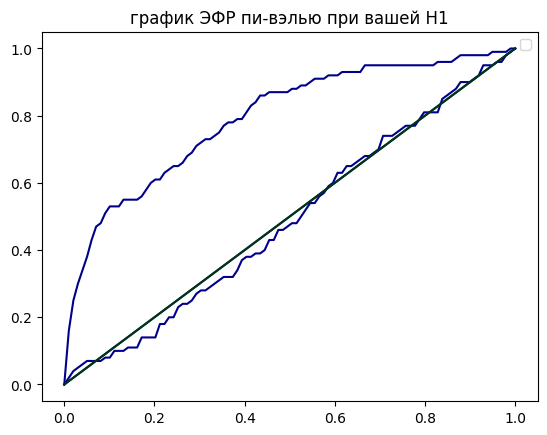

In [5]:
N = 100 #размер выборки пи вэлью
n = 2000 # размер выборки на основе которой считаю статистику
k = int(np.ceil(n**(0.2)))
pval = [0]*N
nu_theor = [0]*k 
mu_0 = 4
sigma2_0 = 8
nu_obs = [0]*k


def a(x):
    return x
         
def nu_obs_fun(x, k, delta): #выдаёт nu наблюдаемые
    nu = [0]*k
    for j in range(len(x)):
        for i in range(k):
            if x[j]<=delta[i][1] and x[j]>delta[i][0]:
                nu[i]+=1
    return nu

def neg_discr_mle(tetta, nu, delta):
    k = np.size(nu)
    ans = 0
    mu = tetta[0]
    sigma = tetta[1]
    for j in range (k):
        if (nu[j] != 0):
            ans+= nu[j]*(np.log(sc.stats.norm.cdf(delta[j][1], mu, sigma) - sc.stats.norm.cdf(delta[j][0], mu, sigma)))
    return((-1)*ans)

    
def deltas_normal(x, k): #выдаёт разбиение прямой
    mu = np.mean(x)
    sigma2 = np.var(x)
    return([[sc.stats.norm.ppf((i)/k, mu, np.sqrt(sigma2)), sc.stats.norm.ppf((i+1)/k, mu, np.sqrt(sigma2)) ] for i in range(k)])


    
bounds = [(None, None), (1e-8, None)] #для максимизации
for j in range(N):
    x = np.random.normal(mu_0, np.sqrt(sigma2_0), size = n)
    delta = deltas_normal(x, k)
    nu_obs = nu_obs_fun(x, k, delta)

  
    #максимизация
    x0 = np.array([np.mean(x), np.std(x)]) #начальное приближение
    res = sc.optimize.minimize(neg_discr_mle, x0, args=(nu_obs, delta), method='L-BFGS-B', bounds = bounds)
    mu, sigma = res.x

    nu_theor = [n*(sc.stats.norm.cdf(delta[i][1], mu, sigma) - sc.stats.norm.cdf(delta[i][0], mu, sigma)) for i in range(k)]
    stat, d = sc.stats.chisquare(nu_obs,  nu_theor)   
    pval[j] = 1-sc.stats.chi2.cdf(stat, df = k-3)

b = ft.partial(a,pval)
get_pvalue_info_H1 (b, level_array = [0.05, 0.01], mode_output = 1)


for j in range(N):
    x = sc.stats.t.rvs(4, size = n)
    delta = deltas_normal(x, k)
    nu_obs = nu_obs_fun(x, k, delta)

  
    #максимизация
    x0 = np.array([np.mean(x), np.std(x)]) #начальное приближение
    res = sc.optimize.minimize(neg_discr_mle, x0, args=(nu_obs, delta), method='L-BFGS-B', bounds = bounds)
    mu, sigma = res.x

    nu_theor = [n*(sc.stats.norm.cdf(delta[i][1], mu, sigma) - sc.stats.norm.cdf(delta[i][0], mu, sigma)) for i in range(k)]
    stat, d = sc.stats.chisquare(nu_obs,  nu_theor)   
    pval[j] = 1-sc.stats.chi2.cdf(stat, df = k-3)

b = ft.partial(a,pval)
get_pvalue_info_H1 (b, level_array = [0.05, 0.01], mode_output = 1)

In [ ]:
хи квадрат проверки нормальности
дискретизация делением выборки на равные части

C:\Users\MI\AppData\Local\Temp\ipykernel_5568\634817638.py:25: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


[0.13999999999999999, 0.05]

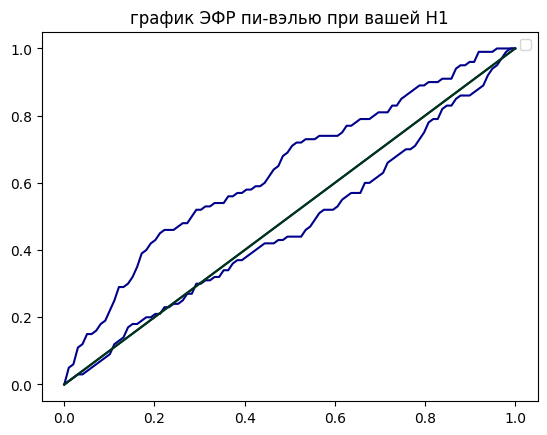

In [8]:
N = 100 #размер выборки пи вэлью
n = 2000 # размер выборки на основе которой считаю статистику
k = int(np.ceil(n**(0.2)))
pval = [0]*N

nu_theor = [0]*k 
mu_0 = 8
sigma2_0 = 8
nu_obs = [0]*k

def a(x):
    return x
         
def nu_obs_fun(x, k, delta): #выдаёт nu наблюдаемые
    nu = [0]*k
    for j in range(len(x)):
        for i in range(k):
            if x[j]<=delta[i][1] and x[j]>delta[i][0]:
                nu[i]+=1
    return nu

def neg_discr_mle(tetta, nu, delta):
    k = np.size(nu)
    ans = 0
    mu = tetta[0]
    sigma = tetta[1]
    for j in range (k):
        if (nu[j] != 0):
            ans+= nu[j]*(np.log(sc.stats.norm.cdf(delta[j][1], mu, sigma) - sc.stats.norm.cdf(delta[j][0], mu, sigma)))
    return((-1)*ans)

    
def deltas_uniform(x, k): #выдаёт разбиение прямой
    y = np.sort(x)
    delta = [[0,0]]*k
    delta[0] = [float('-inf'),y[int(n/k)]]
    delta[k-1] = [y[int((k-1)*n/k)], float('inf')]
    for j in range(k-2):
        delta[j+1] = [y[int((j+1)*n/k)], y[int((j+2)*n/k)]]
    return delta


    
bounds = [(None, None), (1e-8, None)] #для максимизации
for j in range(N):
    x = np.random.normal(mu_0, np.sqrt(sigma2_0), size = n)
    delta = deltas_uniform(x, k)
    nu_obs = nu_obs_fun(x, k, delta)
  
    #максимизация
    x0 = np.array([np.mean(x), np.std(x)]) #начальное приближение
    res = sc.optimize.minimize(neg_discr_mle, x0, args=(nu_obs, delta), method='L-BFGS-B', bounds = bounds)
    mu, sigma = res.x

    nu_theor = [n*(sc.stats.norm.cdf(delta[i][1], mu, sigma) - sc.stats.norm.cdf(delta[i][0], mu, sigma)) for i in range(k)]
    stat, d = sc.stats.chisquare(nu_obs,  nu_theor)   
    pval[j] = 1-sc.stats.chi2.cdf(stat, df = k-3)

b = ft.partial(a,pval)
get_pvalue_info_H1 (b, level_array = [0.05, 0.01], mode_output = 1)



for j in range(N):
    x = sc.stats.t.rvs(4, size = n)
    delta = deltas_uniform(x, k)
    nu_obs = nu_obs_fun(x, k, delta)

  
    #максимизация
    x0 = np.array([np.mean(x), np.std(x)]) #начальное приближение
    res = sc.optimize.minimize(neg_discr_mle, x0, args=(nu_obs, delta), method='L-BFGS-B', bounds = bounds)
    mu, sigma = res.x

    nu_theor = [n*(sc.stats.norm.cdf(delta[i][1], mu, sigma) - sc.stats.norm.cdf(delta[i][0], mu, sigma)) for i in range(k)]
    stat, d = sc.stats.chisquare(nu_obs,  nu_theor)   
    pval[j] = 1-sc.stats.chi2.cdf(stat, df = k-3)

b = ft.partial(a,pval)
get_pvalue_info_H1 (b, level_array = [0.05, 0.01], mode_output = 1)

In [ ]:
Исследовать сгенерированные модельные данные X на нормальность, где
• Xi имеют распределение Вейбулла с параметром формы λ;

i) Использовать критерий из первого пункта, ii) использовать встроенный критерий Андерсона-Дарлинга
(scipy.stats.anderson), а также критерии Шапиро-Уилко (scipy.stats.shapiro) и Д’Агостино
(scipy.stats.normaltest). Построить ЭФР p-value и график мощности. Подобрать размер выборки так,
чтобы сравнение было осмысленным.

weibull 1


C:\Users\MI\AppData\Local\Temp\ipykernel_5568\634817638.py:25: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


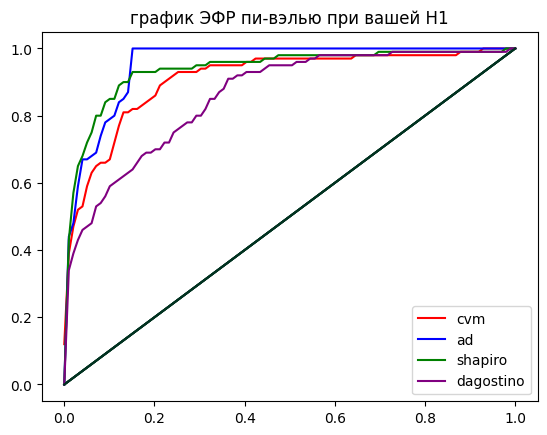

In [9]:
cvm_loaded = np.loadtxt('complex_cvm_values(normal).txt')

lamda = 1

def F(x, mu, sigma2):
    return sc.stats.norm.cdf(x, mu, np.sqrt(sigma2))
    
def norm_cvm_stat(n, x):
    y = np.sort(x)
    return(1/(12*n)+np.sum([((2*i-1)/(2*n) - F(y[i-1], np.mean(x), np.var(x)))**2 for i in range(1, n)]))
    
N = 100 #размер выборки пи вэлью
n = 15 # размер выборки на основе которой считаю статистику
cvm = [0]*N

pval_cvm = [0]*N
pval_ad = [0]*N
pval_shapiro = [0]*N
pval_dagostino = [0]*N

for k in range(N):
    x = np.random.weibull(a = lamda, size = n)
    pval_cvm[k] = 1 - sc.stats.ecdf(cvm_loaded).cdf.evaluate(norm_cvm_stat(n, x))
    pval_ad[k] = sc.stats.anderson(x, dist = "norm", method="interpolate").pvalue
    pval_shapiro[k] = sc.stats.shapiro(x).pvalue
    pval_dagostino[k] = sc.stats.normaltest(x).pvalue
    
def a(x):
    return(x)

print("weibull", lamda)
b = ft.partial(a,pval_cvm)
get_pvalue_info_H1 (b, clr = "red", label = "cvm",level_array = [0.05, 0.01], mode_output = 1)

b = ft.partial(a,pval_ad)
get_pvalue_info_H1 (b, clr = "blue", label = "ad", level_array = [0.05, 0.01], mode_output = 1)

b = ft.partial(a,pval_shapiro)
get_pvalue_info_H1 (b, clr = "green", label = "shapiro", level_array = [0.05, 0.01], mode_output = 1)

b = ft.partial(a,pval_dagostino)
get_pvalue_info_H1 (b, clr = "purple", label = "dagostino", level_array = [0.05, 0.01], mode_output = 1)
plt.legend()

chi2 5


C:\Users\MI\AppData\Local\Temp\ipykernel_4776\634817638.py:25: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


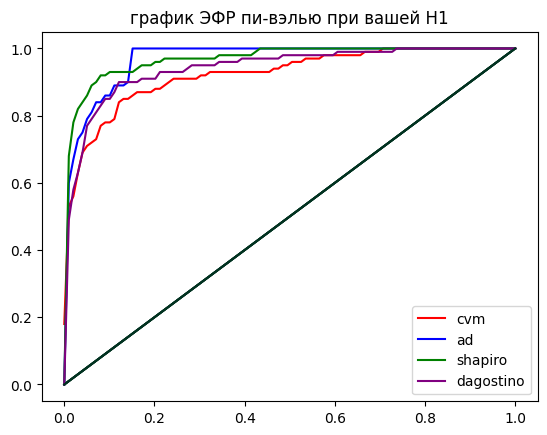

chi2 10


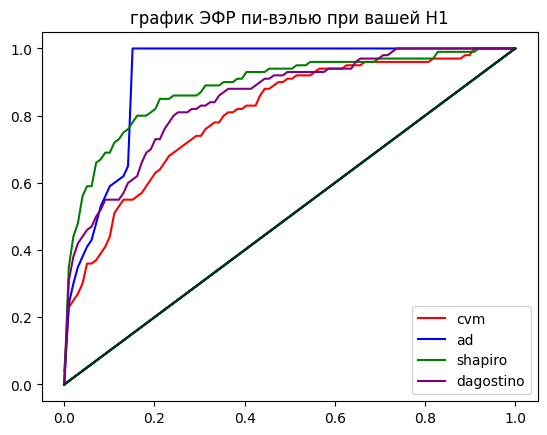

chi2 25


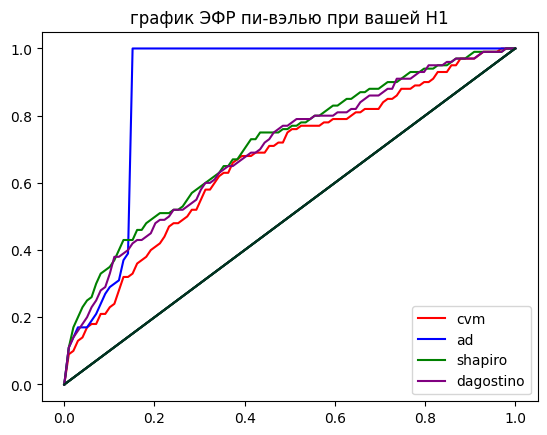

In [34]:
for df in [5,10,25]:
    
    cvm_loaded = np.loadtxt('complex_cvm_values(normal).txt')
    
    def F(x, mu, sigma2):
        return sc.stats.norm.cdf(x, mu, np.sqrt(sigma2))
        
    def norm_cvm_stat(n, x):
        y = np.sort(x)
        return(1/(12*n)+np.sum([((2*i-1)/(2*n) - F(y[i-1], np.mean(x), np.var(x)))**2 for i in range(1, n)]))
        
    N = 100 #размер выборки пи вэлью
    n = 50 # размер выборки на основе которой считаю статистику
    cvm = [0]*N
    
    pval_cvm = [0]*N
    pval_ad = [0]*N
    pval_shapiro = [0]*N
    pval_dagostino = [0]*N
    
    for k in range(N):
        x = np.random.chisquare(df, n)
        pval_cvm[k] = 1 - sc.stats.ecdf(cvm_loaded).cdf.evaluate(norm_cvm_stat(n, x))
        pval_ad[k] = sc.stats.anderson(x, dist = "norm", method="interpolate").pvalue
        pval_shapiro[k] = sc.stats.shapiro(x).pvalue
        pval_dagostino[k] = sc.stats.normaltest(x).pvalue
        
    def a(x):
        return(x)
    
    print("chi2", df)
    b = ft.partial(a,pval_cvm)
    get_pvalue_info_H1 (b, clr = "red", label = "cvm",level_array = [0.05, 0.01], mode_output = 1)
    
    b = ft.partial(a,pval_ad)
    get_pvalue_info_H1 (b, clr = "blue", label = "ad", level_array = [0.05, 0.01], mode_output = 1)
    
    b = ft.partial(a,pval_shapiro)
    get_pvalue_info_H1 (b, clr = "green", label = "shapiro", level_array = [0.05, 0.01], mode_output = 1)
    
    b = ft.partial(a,pval_dagostino)
    get_pvalue_info_H1 (b, clr = "purple", label = "dagostino", level_array = [0.05, 0.01], mode_output = 1)
    plt.legend()
    plt.show()

binom 0.5 50


C:\Users\MI\AppData\Local\Temp\ipykernel_4776\634817638.py:25: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


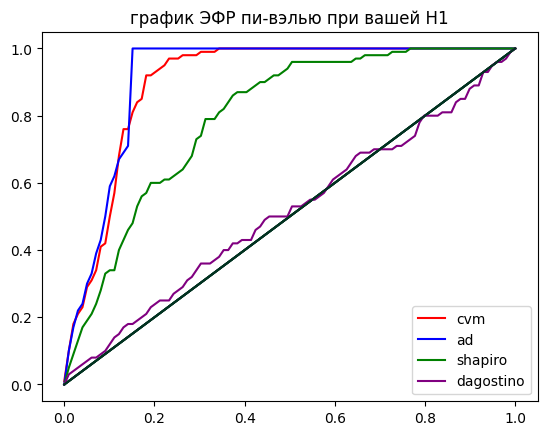

binom 0.5 100


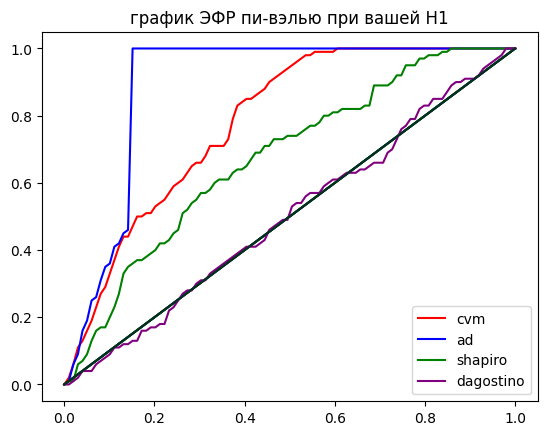

binom 0.5 250


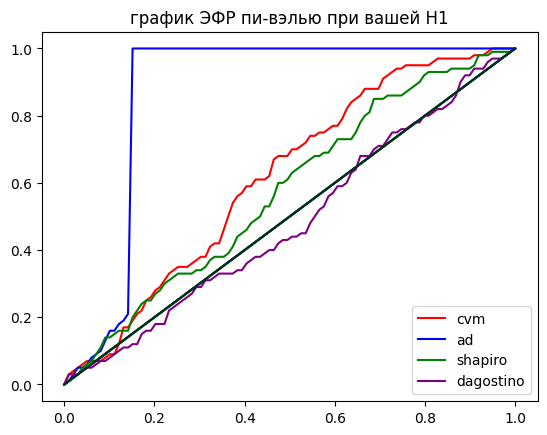

In [46]:
for m in [50,100,250]:
    
    cvm_loaded = np.loadtxt('complex_cvm_values(normal).txt')
    
    
    def F(x, mu, sigma2):
        return sc.stats.norm.cdf(x, mu, np.sqrt(sigma2))
        
    def norm_cvm_stat(n, x):
        y = np.sort(x)
        return(1/(12*n)+np.sum([((2*i-1)/(2*n) - F(y[i-1], np.mean(x), np.var(x)))**2 for i in range(1, n)]))
        
    N = 100 #размер выборки пи вэлью
    n = 100 # размер выборки на основе которой считаю статистику
    cvm = [0]*N
    
    pval_cvm = [0]*N
    pval_ad = [0]*N
    pval_shapiro = [0]*N
    pval_dagostino = [0]*N
    
    for k in range(N):
        x = np.random.binomial(m, 0.5, size = n)
        pval_cvm[k] = 1 - sc.stats.ecdf(cvm_loaded).cdf.evaluate(norm_cvm_stat(n, x))
        pval_ad[k] = sc.stats.anderson(x, dist = "norm", method="interpolate").pvalue
        pval_shapiro[k] = sc.stats.shapiro(x).pvalue
        pval_dagostino[k] = sc.stats.normaltest(x).pvalue
        
    def a(x):
        return(x)
    
    print("binom 0.5", m)
    b = ft.partial(a,pval_cvm)
    get_pvalue_info_H1 (b, clr = "red", label = "cvm",level_array = [0.05, 0.01], mode_output = 1)
    
    b = ft.partial(a,pval_ad)
    get_pvalue_info_H1 (b, clr = "blue", label = "ad", level_array = [0.05, 0.01], mode_output = 1)
    
    b = ft.partial(a,pval_shapiro)
    get_pvalue_info_H1 (b, clr = "green", label = "shapiro", level_array = [0.05, 0.01], mode_output = 1)
    
    b = ft.partial(a,pval_dagostino)
    get_pvalue_info_H1 (b, clr = "purple", label = "dagostino", level_array = [0.05, 0.01], mode_output = 1)
    plt.legend()
    plt.show()

In [ ]:
мощность

weibull


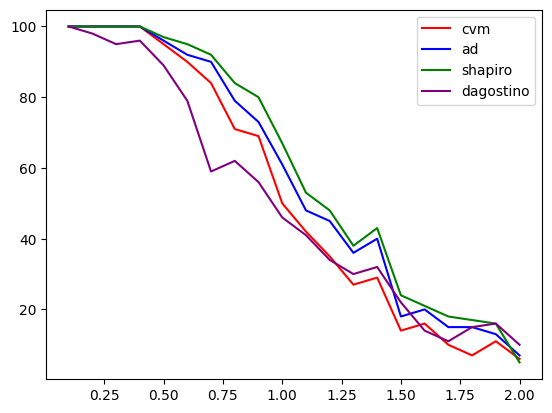

In [15]:
def a(x):
    return(x)

def F(x, mu, sigma2):
    return sc.stats.norm.cdf(x, mu, np.sqrt(sigma2))
        
def norm_cvm_stat(n, x):
    y = np.sort(x)
    return(1/(12*n)+np.sum([((2*i-1)/(2*n) - F(y[i-1], np.mean(x), np.var(x)))**2 for i in range(1, n)]))


power_cvm = [0]*20
power_ad = [0]*20
power_shapiro = [0]*20
power_dagostino = [0]*20
pval_cvm = [0]*N
pval_ad = [0]*N
pval_shapiro = [0]*N
pval_dagostino = [0]*N
cvm_loaded = np.loadtxt('complex_cvm_values(normal).txt')

N = 100 #размер выборки пи вэлью
n = 15 # размер выборки на основе которой считаю статистику
cvm = [0]*N

l = np.linspace(0.1, 2, 20) 

for j in range(20):
    lamda = l[j]
    df = j+1
    for k in range(N):
        x = np.random.weibull(a = lamda, size = n)
        pval_cvm[k] = 1 - sc.stats.ecdf(cvm_loaded).cdf.evaluate(norm_cvm_stat(n, x))
        pval_ad[k] = sc.stats.anderson(x, dist = "norm", method="interpolate").pvalue
        pval_shapiro[k] = sc.stats.shapiro(x).pvalue
        pval_dagostino[k] = sc.stats.normaltest(x).pvalue
        if (1 - sc.stats.ecdf(cvm_loaded).cdf.evaluate(norm_cvm_stat(n, x)) <=0.05):
            power_cvm[j]+=1
        if (sc.stats.anderson(x, dist = "norm", method="interpolate").pvalue <=0.05):
            power_ad[j]+=1
        if (sc.stats.shapiro(x).pvalue<=0.05):
            power_shapiro[j]+=1
        if (sc.stats.normaltest(x).pvalue <=0.05):
            power_dagostino[j]+=1

print("weibull")
plt.plot(l, power_cvm, label = "cvm", color = "red")
plt.plot(l, power_ad, label = "ad", color = "blue")
plt.plot(l, power_shapiro, label = "shapiro", color = "green")
plt.plot(l, power_dagostino, label = "dagostino", color = "purple")
plt.legend()
plt.show()

chi2


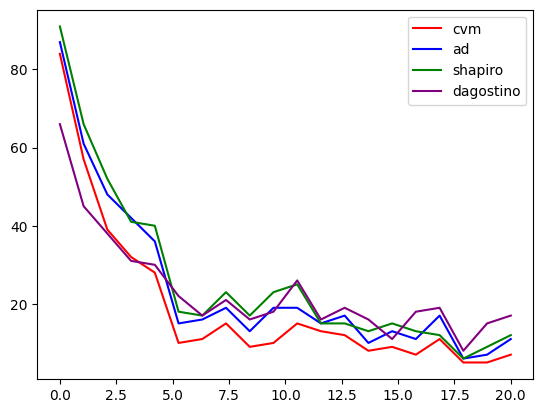

In [17]:
def a(x):
    return(x)

def F(x, mu, sigma2):
    return sc.stats.norm.cdf(x, mu, np.sqrt(sigma2))
        
def norm_cvm_stat(n, x):
    y = np.sort(x)
    return(1/(12*n)+np.sum([((2*i-1)/(2*n) - F(y[i-1], np.mean(x), np.var(x)))**2 for i in range(1, n)]))


power_cvm = [0]*20
power_ad = [0]*20
power_shapiro = [0]*20
power_dagostino = [0]*20
pval_cvm = [0]*N
pval_ad = [0]*N
pval_shapiro = [0]*N
pval_dagostino = [0]*N
cvm_loaded = np.loadtxt('complex_cvm_values(normal).txt')

N = 100 #размер выборки пи вэлью
n = 15 # размер выборки на основе которой считаю статистику
cvm = [0]*N

l = np.linspace(0, 20, 20) 

for j in range(20):
    df = j+1
    for k in range(N):
        x = np.random.chisquare(df, n)
        pval_cvm[k] = 1 - sc.stats.ecdf(cvm_loaded).cdf.evaluate(norm_cvm_stat(n, x))
        pval_ad[k] = sc.stats.anderson(x, dist = "norm", method="interpolate").pvalue
        pval_shapiro[k] = sc.stats.shapiro(x).pvalue
        pval_dagostino[k] = sc.stats.normaltest(x).pvalue
        if (1 - sc.stats.ecdf(cvm_loaded).cdf.evaluate(norm_cvm_stat(n, x)) <=0.05):
            power_cvm[j]+=1
        if (sc.stats.anderson(x, dist = "norm", method="interpolate").pvalue <=0.05):
            power_ad[j]+=1
        if (sc.stats.shapiro(x).pvalue<=0.05):
            power_shapiro[j]+=1
        if (sc.stats.normaltest(x).pvalue <=0.05):
            power_dagostino[j]+=1

print("chi2")
plt.plot(l, power_cvm, label = "cvm", color = "red")
plt.plot(l, power_ad, label = "ad", color = "blue")
plt.plot(l, power_shapiro, label = "shapiro", color = "green")
plt.plot(l, power_dagostino, label = "dagostino", color = "purple")
plt.legend()
plt.show()

binom


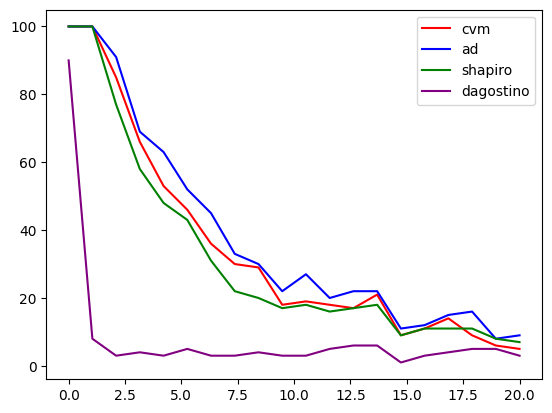

In [19]:
def a(x):
    return(x)

def F(x, mu, sigma2):
    return sc.stats.norm.cdf(x, mu, np.sqrt(sigma2))
        
def norm_cvm_stat(n, x):
    y = np.sort(x)
    return(1/(12*n)+np.sum([((2*i-1)/(2*n) - F(y[i-1], np.mean(x), np.var(x)))**2 for i in range(1, n)]))


power_cvm = [0]*20
power_ad = [0]*20
power_shapiro = [0]*20
power_dagostino = [0]*20
pval_cvm = [0]*N
pval_ad = [0]*N
pval_shapiro = [0]*N
pval_dagostino = [0]*N
cvm_loaded = np.loadtxt('complex_cvm_values(normal).txt')

N = 100 #размер выборки пи вэлью
n = 15 # размер выборки на основе которой считаю статистику
cvm = [0]*N

l = np.linspace(0, 20, 20) 

for j in range(20):
    m = j+1
    for k in range(N):
        x = np.random.binomial(m, 0.5, size = n)
        pval_cvm[k] = 1 - sc.stats.ecdf(cvm_loaded).cdf.evaluate(norm_cvm_stat(n, x))
        pval_ad[k] = sc.stats.anderson(x, dist = "norm", method="interpolate").pvalue
        pval_shapiro[k] = sc.stats.shapiro(x).pvalue
        pval_dagostino[k] = sc.stats.normaltest(x).pvalue
        if (1 - sc.stats.ecdf(cvm_loaded).cdf.evaluate(norm_cvm_stat(n, x)) <=0.05):
            power_cvm[j]+=1
        if (sc.stats.anderson(x, dist = "norm", method="interpolate").pvalue <=0.05):
            power_ad[j]+=1
        if (sc.stats.shapiro(x).pvalue<=0.05):
            power_shapiro[j]+=1
        if (sc.stats.normaltest(x).pvalue <=0.05):
            power_dagostino[j]+=1

print("binom")
plt.plot(l, power_cvm, label = "cvm", color = "red")
plt.plot(l, power_ad, label = "ad", color = "blue")
plt.plot(l, power_shapiro, label = "shapiro", color = "green")
plt.plot(l, power_dagostino, label = "dagostino", color = "purple")
plt.legend()
plt.show()

In [ ]:
проверка экспоненциального для 
i) встроенный критерий Андерсона-Дарлинга 
ii) критерий из первого пункта, а также критерии 
а)
Шапиро-Уилка, 
б) Жанга и 
в) Фрозини.

In [ ]:
(a) Xi имеют распределение |N (μ, 1)|;

C:\Users\MI\AppData\Local\Temp\ipykernel_13992\1632089380.py:25: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


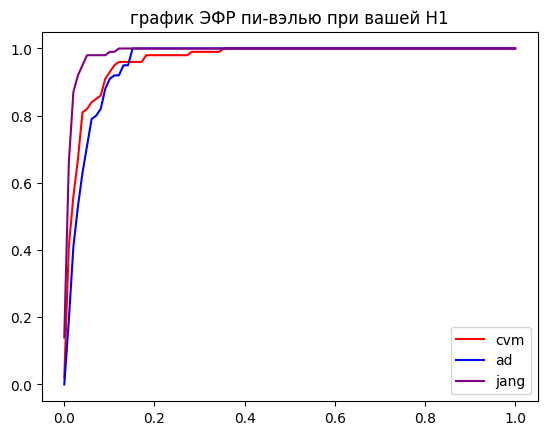

In [45]:
def a(x):
    return(x)

def F(x, tetta_hat):
    return sc.stats.expon.cdf(x, scale = tetta_hat)
    
def cvm_stat(x):
    n = len(x)
    y = np.sort(x)
    return(1/(12*n)+np.sum([((2*i-1)/(2*n) - F(y[i-1], np.mean(x)))**2 for i in range(1, n)]))

def j_stat(x):
    n = len(x)
    tetta_hat = np.mean(x)
    w = [ sc.stats.expon.cdf(x[j], scale = tetta_hat) for j in range(n) ]
    z = np.sort(w)
    return (-1)*np.sum( [ np.log(z[j]) / (n-j-0.5) +  np.log(1-z[j]) / (j+0.5) for j in range(n) ] )

def generator_abs_norm(mu, n):
    x = np.random.normal(mu,1,n)
    return [np.abs(a) for a in x]

cvm_loaded = np.loadtxt('complex_cvm_values(expon).txt')

j_loaded = np.loadtxt('complex_jang_values(expon).txt')

p = 0.5
df = 7
mu = 1
N = 100 #размер выборки пи вэлью
n = 10 # размер выборки на основе которой считаю статистику
pval_ad = [0]*N
pval_cvm = [0]*N
pval_j = [0]*N


for k in range(N):
    y = np.random.exponential(scale = 2, size = n)
    z = generator_abs_norm(mu, n)
    ch = np.random.chisquare(df, n)
    g = np.random.geometric(p, n)
    x = g
    pval_ad[k] = sc.stats.anderson(x, dist = "expon", method="interpolate").pvalue
    pval_cvm[k] = 1 - sc.stats.ecdf(cvm_loaded).cdf.evaluate(cvm_stat(x))
    pval_j[k] = 1 - sc.stats.ecdf(j_loaded).cdf.evaluate(j_stat(x))

b = ft.partial(a,pval_cvm)
get_pvalue_info_H1 (b, clr = "red", label = "cvm",level_array = [0.05, 0.01], mode_output = 1)

b = ft.partial(a,pval_ad)
get_pvalue_info_H1 (b, clr = "blue", label = "ad", level_array = [0.05, 0.01], mode_output = 1)


b = ft.partial(a,pval_j)
get_pvalue_info_H1 (b, clr = "purple", label = "jang", level_array = [0.05, 0.01], mode_output = 1)


plt.legend()


In [ ]:
power

|norm|


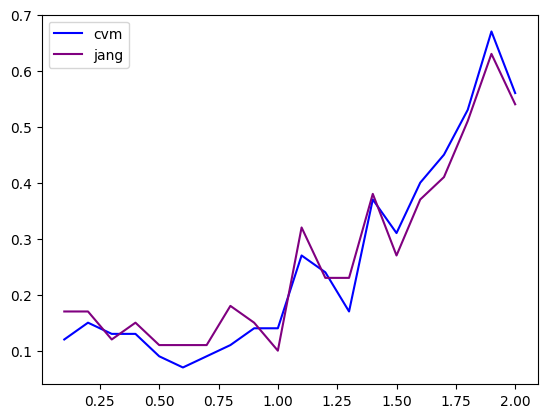

chi2


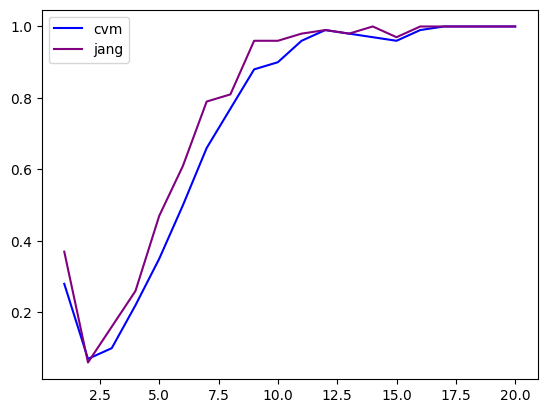

geom


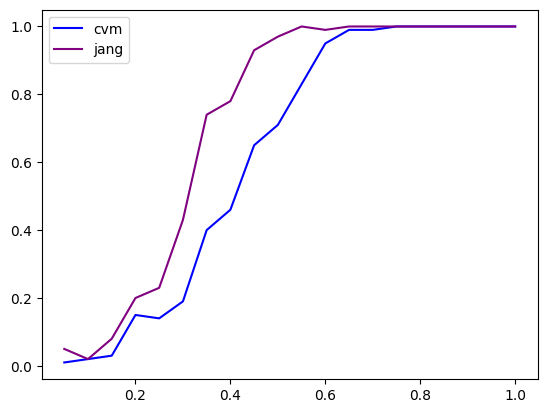

In [7]:
def a(x):
    return(x)

def F(x, tetta_hat):
    return sc.stats.expon.cdf(x, scale = tetta_hat)
    
def cvm_stat(x):
    n = len(x)
    y = np.sort(x)
    return(1/(12*n)+np.sum([((2*i-1)/(2*n) - F(y[i-1], np.mean(x)))**2 for i in range(1, n)]))

def j_stat(x):
    n = len(x)
    tetta_hat = np.mean(x)
    w = [ sc.stats.expon.cdf(x[j], scale = tetta_hat) for j in range(n) ]
    z = np.sort(w)
    return (-1)*np.sum( [ np.log(z[j]) / (n-j-0.5) +  np.log(1-z[j]) / (j+0.5) for j in range(n) ] )

def generator_abs_norm(mu, n):
    x = np.random.normal(mu,1,n)
    return [np.abs(a) for a in x]

cvm_loaded = np.loadtxt('complex_cvm_values(expon).txt')

j_loaded = np.loadtxt('complex_jang_values(expon).txt')


N = 100 #размер выборки пи вэлью
n = 10 # размер выборки на основе которой считаю статистику
pval_ad = [0]*N
pval_cvm = [0]*N
pval_j = [0]*N

ad_power = [0]*20
cvm_power = [0]*20
j_power = [0]*20

for j in range(20):
    p = (j+1)/20
    df = j+1
    mu = j/10
    for k in range(N):
        y = np.random.exponential(scale = 2, size = n)
        z = generator_abs_norm(mu, n)
        ch = np.random.chisquare(df, n)
        g = np.random.geometric(p, n)
        x = z
        pval_ad[k] = sc.stats.anderson(x, dist = "expon", method="interpolate").pvalue
        pval_cvm[k] = 1 - sc.stats.ecdf(cvm_loaded).cdf.evaluate(cvm_stat(x))
        pval_j[k] = 1 - sc.stats.ecdf(j_loaded).cdf.evaluate(j_stat(x))
        if(pval_ad[k]<=0.05):
            ad_power[j]+=1/N
        if(pval_cvm[k]<=0.05):
            cvm_power[j]+=1/N
        if(pval_j[k]<=0.05):
            j_power[j]+=1/N
print("|norm|")
#plt.plot([(s+1)/10 for s in range(20)], ad_power, label = "ad", color = "red")
plt.plot([(s+1)/10 for s in range(20)], cvm_power, label = "cvm", color = "blue")
plt.plot([(s+1)/10 for s in range(20)], j_power, label ="jang", color = "purple")
plt.legend()
plt.show()


ad_power = [0]*20
cvm_power = [0]*20
j_power = [0]*20

for j in range(20):
    p = (j+1)/20
    df = j+1
    mu = j/10
    for k in range(N):
        y = np.random.exponential(scale = 2, size = n)
        z = generator_abs_norm(mu, n)
        ch = np.random.chisquare(df, n)
        g = np.random.geometric(p, n)
        x = ch
        pval_ad[k] = sc.stats.anderson(x, dist = "expon", method="interpolate").pvalue
        pval_cvm[k] = 1 - sc.stats.ecdf(cvm_loaded).cdf.evaluate(cvm_stat(x))
        pval_j[k] = 1 - sc.stats.ecdf(j_loaded).cdf.evaluate(j_stat(x))
        if(pval_ad[k]<=0.05):
            ad_power[j]+=1/N
        if(pval_cvm[k]<=0.05):
            cvm_power[j]+=1/N
        if(pval_j[k]<=0.05):
            j_power[j]+=1/N
print("chi2")
#plt.plot([(s+1) for s in range(20)], ad_power, label = "ad", color = "red")
plt.plot([(s+1) for s in range(20)], cvm_power, label = "cvm", color = "blue")
plt.plot([(s+1)for s in range(20)], j_power, label ="jang", color = "purple")
plt.legend()
plt.show()

ad_power = [0]*20
cvm_power = [0]*20
j_power = [0]*20

for j in range(20):
    p = (j+1)/20
    df = j+1
    mu = j/10
    for k in range(N):
        y = np.random.exponential(scale = 2, size = n)
        z = generator_abs_norm(mu, n)
        ch = np.random.chisquare(df, n)
        g = np.random.geometric(p, n)
        x = g
        pval_ad[k] = sc.stats.anderson(x, dist = "expon", method="interpolate").pvalue
        pval_cvm[k] = 1 - sc.stats.ecdf(cvm_loaded).cdf.evaluate(cvm_stat(x))
        pval_j[k] = 1 - sc.stats.ecdf(j_loaded).cdf.evaluate(j_stat(x))
        if(pval_ad[k]<=0.05):
            ad_power[j]+=1/N
        if(pval_cvm[k]<=0.05):
            cvm_power[j]+=1/N
        if(pval_j[k]<=0.05):
            j_power[j]+=1/N
print("geom")
#plt.plot([(s+1)/20 for s in range(20)], ad_power, label = "ad", color = "red")
plt.plot([(s+1)/20 for s in range(20)], cvm_power, label = "cvm", color = "blue")
plt.plot([(s+1)/20 for s in range(20)], j_power, label ="jang", color = "purple")
plt.legend()
plt.show()